# Amazon Product Recommendation System

## Project Overview

This project examines product-rating data to develop and evaluate recommendation approaches for an e-commerce setting. The analysis uses historical user–product ratings to identify patterns in customer preferences and generate personalized product recommendations.

The dataset contains user identifiers, product identifiers, product ratings, and timestamps. The timestamp is excluded from the modeling workflow, which focuses on rating-based recommendation methods.

## Business Context

E-commerce platforms offer large product catalogs, making it difficult for customers to identify products that match their interests. Recommendation systems can help address this discovery challenge by using historical interactions to estimate user preferences and rank potentially relevant products.

This case study compares popularity-based recommendations with collaborative-filtering approaches. It evaluates user-user and item-item similarity methods, as well as matrix factorization, to understand how different techniques perform on the available rating data.

## Project Objectives

- Examine the structure, coverage, and distribution of user–product ratings.
- Establish a popularity-based recommendation baseline.
- Build user-user and item-item collaborative-filtering models.
- Develop a matrix-factorization model using Singular Value Decomposition (SVD).
- Tune model hyperparameters and compare baseline and optimized results.
- Evaluate recommendation quality using Precision@K, Recall@K, F1-score@K, and rating prediction error.
- Summarize model trade-offs and practical considerations for deploying a recommendation approach.

## Dataset

The dataset contains the following attributes:

- **userId:** Unique identifier assigned to each user.
- **productId:** Unique identifier assigned to each product.
- **Rating:** User-provided rating for the corresponding product.
- **timestamp:** Time at which the rating was recorded; this field is not used in the current modeling workflow.

## Scope

The analysis is based on historical product ratings. It does not incorporate product descriptions, review text, or additional user and product attributes. Consequently, recommendations are generated from rating behavior rather than content-based features.

The notebook includes reusable functions for generating recommendations and evaluating model performance. These functions are used throughout the analysis to support consistent comparisons across recommendation approaches.

## Environment Setup

The `surprise` library is used for collaborative-filtering and matrix-factorization models. The notebook was developed in a Google Colab environment and uses a mounted Google Drive location to access the source dataset.

Update the data-loading path in the relevant code cell if running this notebook in a different environment.

In [1]:
!pip uninstall numpy -y

Found existing installation: numpy 2.0.2
Uninstalling numpy-2.0.2:
  Successfully uninstalled numpy-2.0.2


In [1]:
!pip install numpy==1.26.0

If the package installation requires a runtime restart, restart the session and continue execution from the library-import section.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
import os
os.chdir('/content/drive/MyDrive/Colab Notebooks')

**Installing surprise library**

In [5]:
!pip install surprise

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 32.4 MB/s eta 0:00:00


## **Importing the necessary libraries and overview of the dataset**

In [6]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np, pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns

from collections import defaultdict

from sklearn.metrics import mean_squared_error

### **Loading the data**
- Import the Dataset
- Add column names ['user_id', 'prod_id', 'rating', 'timestamp']
- Drop the column timestamp
- Copy the data to another DataFrame called **df**

In [8]:
import pandas as pd

# import the dataset
df = pd.read_csv('/content/ratings_Electronics.csv')

# add column names
df.columns = ['user_id', 'prod_id', 'rating', 'timestamp']

# drop the timestamp
df.drop('timestamp', axis=1, inplace=True)

# didn't copy the data to another dataframe to save space. I was having issues with it crashing
print(df.shape)

(7824481, 3)


**As this dataset is very large and has 7,824,482 observations, it is not computationally possible to build a model using this. Moreover, many users have only rated a few products and also some products are rated by very few users. Hence, we can reduce the dataset by considering certain logical assumptions.**

Here, we will be taking users who have given at least 50 ratings, and the products that have at least 5 ratings, as when we shop online we prefer to have some number of ratings of a product.

In [10]:
# Get the column containing the users
users = df.user_id

# Create a dictionary from users to their number of ratings
ratings_count = {}

for user in users:

    # If we already have the user, just add 1 to their rating count
    if user in ratings_count:
        ratings_count[user] += 1

    # Otherwise, set their rating count to 1
    else:
        ratings_count[user] = 1

In [11]:
# We want our users to have at least 50 ratings to be considered
RATINGS_CUTOFF = 50

remove_users = []

for user, num_ratings in ratings_count.items():
    if num_ratings < RATINGS_CUTOFF:
        remove_users.append(user)

df = df.loc[ ~ df.user_id.isin(remove_users)]

In [12]:
# Get the column containing the products
prods = df.prod_id

# Create a dictionary from products to their number of ratings
ratings_count = {}

for prod in prods:

    # If we already have the product, just add 1 to its rating count
    if prod in ratings_count:
        ratings_count[prod] += 1

    # Otherwise, set their rating count to 1
    else:
        ratings_count[prod] = 1

In [13]:
# We want our item to have at least 5 ratings to be considered
RATINGS_CUTOFF = 5

remove_prods = []

for prod, num_ratings in ratings_count.items():
    if num_ratings < RATINGS_CUTOFF:
        remove_prods.append(prod)

df_final = df.loc[~ df.prod_id.isin(remove_prods)]

In [14]:
df = df_final.copy()

del df_final

import gc
gc.collect()

0

In [15]:
print(df.shape)
print(df['user_id'].nunique())
print(df['prod_id'].nunique())

(65290, 3)
1540
5689


In [16]:
# Print a few rows of the imported dataset
df.head()

,user_id,prod_id,rating
1309,A3LDPF5FMB782Z,1400501466,5.0
1321,A1A5KUIIIHFF4U,1400501466,1.0
1334,A2XIOXRRYX0KZY,1400501466,3.0
1450,AW3LX47IHPFRL,1400501466,5.0
1455,A1E3OB6QMBKRYZ,1400501466,1.0


## Exploratory Data Analysis

### Dataset Dimensions

### **Check the number of rows and columns and provide observations.**

In [17]:
# Check the number of rows and columns and provide observations
df.shape

(65290, 3)

### Analysis Observations

There are 65,290 rows and 3 columns

### Data Types

In [18]:
# Check Data types and provide observations
df.dtypes

,0
user_id,object
prod_id,object
rating,float64


### Analysis Observations

user_id and prod_id are both objects meaning they are being stored as text/string while rating is a float because it include decimal values (like 4.0 or 3.5).

### Missing-Value Assessment

In [19]:
# Check for missing values present and provide observations
df.isnull().sum()

,0
user_id,0
prod_id,0
rating,0


### Analysis Observations

There are no missing values

### Rating Distribution and Summary Statistics

In [20]:
# Summary statistics of 'rating' variable and provide observations
df['rating'].describe()

,rating
count,65290.000000
mean,4.294808
std,0.988915
min,1.000000
25%,4.000000
50%,5.000000
75%,5.000000
max,5.000000


### Analysis Observations

The rating variable consists of 65,290 observations with an average rating of 4.29, indicating that users generally give favorable product reviews. The median rating is 5, and both the median and the 75th percentile are equal to 5, showing that a large proportion of ratings are at the highest value. The standard deviation of approximately 0.99 indicates relatively low variability in ratings, while the full range of 1 to 5 confirms that all possible rating levels are represented in the dataset.

### Rating Distribution

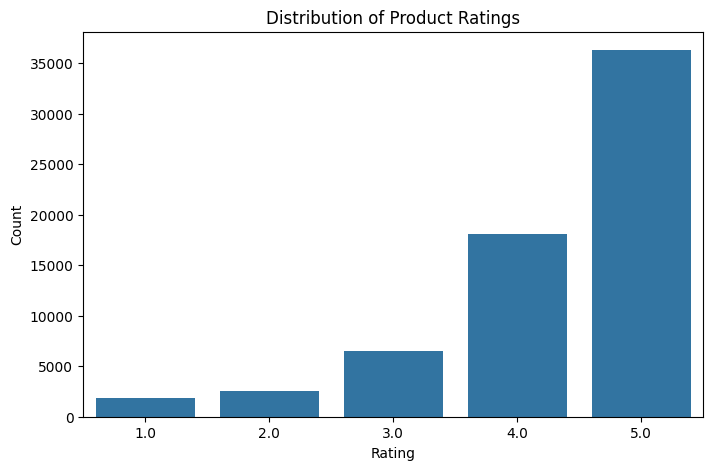

In [21]:
# Create the bar plot and provide observations
plt.figure(figsize=(8,5))
sns.countplot(x='rating', data=df)

plt.title('Distribution of Product Ratings')
plt.xlabel('Rating')
plt.ylabel('Count')

plt.show()

### Analysis Observations

* most ratings are concentrated at 4 and 5
* there are few low ratings (1 and 2)

### User and Product Coverage

In [22]:
# Number of total rows in the data and number of unique user id and product id in the data
print("Number of unique users:", df['user_id'].nunique())
print("Number of unique products:", df['prod_id'].nunique())

Number of unique users: 1540
Number of unique products: 5689


### Analysis Observations

The dataset contains 1,540 unique users and 5689 unique products. There are far more products than users which shows that users have rated only a small portion of the available products, which is common in recommendation systems.  

### Rating Activity by User

In [23]:
# Top 10 users based on the number of ratings
df['user_id'].value_counts().head(10)

,count
user_id,
ADLVFFE4VBT8,295
A3OXHLG6DIBRW8,230
A1ODOGXEYECQQ8,217
A36K2N527TXXJN,212
A25C2M3QF9G7OQ,203
A680RUE1FDO8B,196
A1UQBFCERIP7VJ,193
A22CW0ZHY3NJH8,193
AWPODHOB4GFWL,184


In [24]:
# sum of the top 10 reviewers reviews
top_10 = df['user_id'].value_counts().head(10)
top_10.sum()

2102

### Analysis Observations

The top 10 users contributed a large share of the total ratings with 2102 ratings between them.

**Now that we have explored and prepared the data, let's build the first recommendation system.**

## Model 1: Popularity-Based Recommendation

In [25]:
# Calculate the average rating for each product
df.groupby('prod_id')['rating'].mean()

# Calculate the count of ratings for each product
df.groupby('prod_id')['rating'].count()

# Create a dataframe with calculated average and count of ratings
product_stats = df.groupby('prod_id')['rating'].agg(['mean', 'count']).reset_index()

# Sort the dataframe by average of ratings in the descending order
product_stats.sort_values(by='mean', ascending=False)

# See the first five records of the "final_rating" dataset
final_rating = product_stats.sort_values(
    by=['mean', 'count'],
    ascending=[False, False]
)
final_rating.head()


,prod_id,mean,count
634,B000FQ2JLW,5.0,19
5589,B00ISFNSBW,5.0,18
699,B000IJY8DS,5.0,17
1592,B001TH7GUA,5.0,17
5544,B00HZWJGS8,5.0,17


In [26]:
# Defining a function to get the top n products based on the highest average rating and minimum interactions
def top_n_products(data, n, min_interaction):

    # Calculate average rating and count of ratings
    recommendations = data.groupby('prod_id')['rating'].agg(
        average_rating='mean',
        rating_count='count'
    ).reset_index()

    # Finding products with minimum number of interactions
    recommendations = recommendations[
        recommendations['rating_count'] >= min_interaction
    ]

    # Sorting values with respect to average rating
    recommendations = recommendations.sort_values(
        by=['average_rating', 'rating_count'],
        ascending=[False, False]
    )

    # Return top n products
    return recommendations.head(n)


### **Recommending top 5 products with 50 minimum interactions based on popularity**

In [27]:
top_n_products(df, 5, 50)

,prod_id,average_rating,rating_count
1594,B001TH7GUU,4.871795,78
2316,B003ES5ZUU,4.864130,184
1227,B0019EHU8G,4.855556,90
3877,B006W8U2MU,4.824561,57
850,B000QUUFRW,4.809524,84


### **Recommending top 5 products with 100 minimum interactions based on popularity**

In [28]:
top_n_products(df, 5, 100)

,prod_id,average_rating,rating_count
2316,B003ES5ZUU,4.864130,184
781,B000N99BBC,4.772455,167
2073,B002WE6D44,4.770000,100
4126,B007WTAJTO,4.701220,164
2041,B002V88HFE,4.698113,106


We have recommended the **top 5** products by using the popularity recommendation system. Now, let's build a recommendation system using **collaborative filtering.**

## Model 2: Collaborative Filtering

### Baseline User-User Similarity Model

- Below, we are building **similarity-based recommendation systems** using `cosine` similarity and using **KNN to find similar users** which are the nearest neighbor to the given user.  
- We will be using a new library, called `surprise`, to build the remaining models. Let's first import the necessary classes and functions from this library.

In [29]:
# To compute the accuracy of models
from surprise import accuracy

# Class is used to parse a file containing ratings, data should be in structure - user ; item ; rating
from surprise.reader import Reader

# Class for loading datasets
from surprise.dataset import Dataset

# For tuning model hyperparameters
from surprise.model_selection import GridSearchCV

# For splitting the rating data in train and test datasets
from surprise.model_selection import train_test_split

# For implementing similarity-based recommendation system
from surprise.prediction_algorithms.knns import KNNBasic

# For implementing matrix factorization based recommendation system
from surprise.prediction_algorithms.matrix_factorization import SVD

# for implementing K-Fold cross-validation
from surprise.model_selection import KFold

# For implementing clustering-based recommendation system
from surprise import CoClustering

**Before building the recommendation systems, let's  go over some basic terminologies we are going to use:**

**Relevant item:** An item (product in this case) that is actually **rated higher than the threshold rating** is relevant, if the **actual rating is below the threshold then it is a non-relevant item**.  

**Recommended item:** An item that's **predicted rating is higher than the threshold is a recommended item**, if the **predicted rating is below the threshold then that product will not be recommended to the user**.  


**False Negative (FN):** It is the **frequency of relevant items that are not recommended to the user**. If the relevant items are not recommended to the user, then the user might not buy the product/item. This would result in the **loss of opportunity for the service provider**, which they would like to minimize.

**False Positive (FP):** It is the **frequency of recommended items that are actually not relevant**. In this case, the recommendation system is not doing a good job of finding and recommending the relevant items to the user. This would result in **loss of resources for the service provider**, which they would also like to minimize.

**Recall:** It is the **fraction of actually relevant items that are recommended to the user**, i.e., if out of 10 relevant products, 6 are recommended to the user then recall is 0.60. Higher the value of recall better is the model. It is one of the metrics to do the performance assessment of classification models.

**Precision:** It is the **fraction of recommended items that are relevant actually**, i.e., if out of 10 recommended items, 6 are found relevant by the user then precision is 0.60. The higher the value of precision better is the model. It is one of the metrics to do the performance assessment of classification models.

**While making a recommendation system, it becomes customary to look at the performance of the model. In terms of how many recommendations are relevant and vice-versa, below are some most used performance metrics used in the assessment of recommendation systems.**

### **Precision@k, Recall@ k, and F1-score@k**

**Precision@k** - It is the **fraction of recommended items that are relevant in `top k` predictions**. The value of k is the number of recommendations to be provided to the user. One can choose a variable number of recommendations to be given to a unique user.  


**Recall@k** - It is the **fraction of relevant items that are recommended to the user in `top k` predictions**.

**F1-score@k** - It is the **harmonic mean of Precision@k and Recall@k**. When **precision@k and recall@k both seem to be important** then it is useful to use this metric because it is representative of both of them.

### **Some useful functions**

- Below function takes the **recommendation model** as input and gives the **precision@k, recall@k, and F1-score@k** for that model.  
- To compute **precision and recall**, **top k** predictions are taken under consideration for each user.
- We will use the precision and recall to compute the F1-score.

In [30]:
def precision_recall_at_k(model, k = 10, threshold = 3.5):
    """Return precision and recall at k metrics for each user"""

    # First map the predictions to each user
    user_est_true = defaultdict(list)

    # Making predictions on the test data
    predictions = model.test(testset)

    for uid, _, true_r, est, _ in predictions:
        user_est_true[uid].append((est, true_r))

    precisions = dict()
    recalls = dict()
    for uid, user_ratings in user_est_true.items():

        # Sort user ratings by estimated value
        user_ratings.sort(key = lambda x: x[0], reverse = True)

        # Number of relevant items
        n_rel = sum((true_r >= threshold) for (_, true_r) in user_ratings)

        # Number of recommended items in top k
        n_rec_k = sum((est >= threshold) for (est, _) in user_ratings[:k])

        # Number of relevant and recommended items in top k
        n_rel_and_rec_k = sum(((true_r >= threshold) and (est >= threshold))
                              for (est, true_r) in user_ratings[:k])

        # Precision@K: Proportion of recommended items that are relevant
        # When n_rec_k is 0, Precision is undefined. Therefore, we are setting Precision to 0 when n_rec_k is 0

        precisions[uid] = n_rel_and_rec_k / n_rec_k if n_rec_k != 0 else 0

        # Recall@K: Proportion of relevant items that are recommended
        # When n_rel is 0, Recall is undefined. Therefore, we are setting Recall to 0 when n_rel is 0

        recalls[uid] = n_rel_and_rec_k / n_rel if n_rel != 0 else 0

    # Mean of all the predicted precisions are calculated.
    precision = round((sum(prec for prec in precisions.values()) / len(precisions)), 3)

    # Mean of all the predicted recalls are calculated.
    recall = round((sum(rec for rec in recalls.values()) / len(recalls)), 3)

    accuracy.rmse(predictions)

    print('Precision: ', precision) # Command to print the overall precision

    print('Recall: ', recall) # Command to print the overall recall

    print('F_1 score: ', round((2*precision*recall)/(precision+recall), 3)) # Formula to compute the F-1 score

### Evaluation Configuration

Precision@K and Recall@K are calculated using a relevance threshold of 3.5 and a recommendation cutoff of K = 10. These settings define which ratings are treated as relevant and how many recommendations are evaluated for each user.

Below we are loading the **`rating` dataset**, which is a **pandas DataFrame**, into a **different format called `surprise.dataset.DatasetAutoFolds`**, which is required by this library. To do this, we will be **using the classes `Reader` and `Dataset`.**

In [31]:
# Instantiating Reader scale with expected rating scale
reader = Reader(rating_scale = (1, 5))

# Loading the rating dataset
data = Dataset.load_from_df(df[['user_id', 'prod_id', 'rating']], reader)

# Splitting the data into train and test datasets
trainset, testset = train_test_split(data, test_size = 0.2, random_state = 42)

Now, we are **ready to build the first baseline similarity-based recommendation system** using the cosine similarity.

### User-User Similarity-Based Recommendations

In [32]:
# define the evalution function
def precision_recall_at_k(predictions, k=10, threshold=3.5):

    user_est_true = defaultdict(list)

    for uid, _, true_r, est, _ in predictions:
        user_est_true[uid].append((est, true_r))

    precisions = {}
    recalls = {}

    for uid, user_ratings in user_est_true.items():

        user_ratings.sort(key=lambda x: x[0], reverse=True)

        n_rel = sum(true_r >= threshold for (_, true_r) in user_ratings)
        n_rec_k = sum(est >= threshold for (est, _) in user_ratings[:k])

        n_rel_and_rec_k = sum(
            (true_r >= threshold and est >= threshold)
            for (est, true_r) in user_ratings[:k]
        )

        precisions[uid] = n_rel_and_rec_k / n_rec_k if n_rec_k else 0
        recalls[uid] = n_rel_and_rec_k / n_rel if n_rel else 0

    precision = sum(precisions.values()) / len(precisions)
    recall = sum(recalls.values()) / len(recalls)

    f1 = (2 * precision * recall) / (precision + recall)

    return precision, recall, f1

In [33]:
# build and train the model
# Delare the similarity options
sim_options = {
    'name': 'cosine',
    'user_based': True
}
# Initialize the KNNBasic Model using sim_options declared, Verbose = False, and setting random_state = 1
sim_user_user = KNNBasic(
    sim_options=sim_options,
    verbose=False
)

# Fit the model on the training data
sim_user_user.fit(trainset)

In [34]:
# make predictions and evaluate
predictions = sim_user_user.test(testset)

#Let us compute precision@k, recall@k, and f_1 score using the precision recall at k function defined above
precision, recall, f1 = precision_recall_at_k(
    predictions,
    k=10,
    threshold=3.5
)

print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

Precision: 0.855472164711294
Recall: 0.8577797068198287
F1-score: 0.856624381776136


### Analysis Observations

1. High precision

The model achieved a precision of 85.54% which means that most of the products it recommends are relevant to users.

2. Strong recall

The recall of 85.77% shows that the model is able to capture a good portion of the relevant products available for users. This means it is fairly effective at identifying items users are likely to prefer.

3. Balanced performance

The F1 score of 85.66% suggests a strong balance between precision and recall. This indicates the model performs consistently without sacrificing too much accuracy for coverage.

Let's now **predict rating for a user with `userId=A3LDPF5FMB782Z` and `productId=1400501466`** as shown below. Here the user has already interacted or watched the product with productId '1400501466' and given a rating of 5.

In [35]:
# Predicting rating for a sample user with an interacted product
sim_user_user.predict('A3LDPF5FMB782Z', '1400501466')

Prediction(uid='A3LDPF5FMB782Z', iid='1400501466', r_ui=None, est=3.4, details={'actual_k': 5, 'was_impossible': False})

### Analysis Observations

The model predicted a rating of 3.4 for the user on this product while the actual rating was 5. This indicates that the model underestimated the user's preference for the product by about 1.6 points. This predicition was based on 5 neighbouring users, suggesting that the similarity-based approach had sufficient information but may not have fully captured this user's specific preference.

Below is the **list of users who have not seen the product with product id "1400501466"**.

In [36]:
# Find unique user_id where prod_id is not equal to "1400501466"
all_users = df['user_id'].unique()

# Users who have already rated this product
seen_users = df[df['prod_id'] == '1400501466']['user_id'].unique()

# Users who have NOT rated this product
not_seen_users = [user for user in all_users if user not in seen_users]

* It can be observed from the above list that **user "A34BZM6S9L7QI4" has not seen the product with productId "1400501466"** as this userId is a part of the above list.

**Below we are predicting rating for `userId=A34BZM6S9L7QI4` and `prod_id=1400501466`.**

In [37]:
# Predicting rating for a sample user with a non interacted product
sim_user_user.predict('A34BZM6S9L7QI4', '1400501466')

Prediction(uid='A34BZM6S9L7QI4', iid='1400501466', r_ui=None, est=4.292024046561495, details={'was_impossible': True, 'reason': 'Not enough neighbors.'})

### Analysis Observations

The model estimated a rating of 4.29 for this user on the product. However, the prediction was marked as impossible because there were not enough similar neighboring users available to generate a reliable user-user collaborative filtering recommendation. As a result, the estimated rating is a fallback prediction rather than one derived from user similarities. This highlights a limitation of collaborative filtering when there is insufficient information about similar users to support personalized recommendations.

### Hyperparameter Optimization: User-User Model

Below, we will be tuning hyperparameters for the `KNNBasic` algorithm. Let's try to understand some of the hyperparameters of the KNNBasic algorithm:

- **k** (int) – The (max) number of neighbors to take into account for aggregation. Default is 40.
- **min_k** (int) – The minimum number of neighbors to take into account for aggregation. If there are not enough neighbors, the prediction is set to the global mean of all ratings. Default is 1.
- **sim_options** (dict) – A dictionary of options for the similarity measure. And there are four similarity measures available in surprise -
    - cosine
    - msd (default)
    - Pearson
    - Pearson baseline

In [38]:
# Setting up parameter grid to tune the hyperparameters
param_grid = {
    'k': [10, 20, 30, 40],
    'min_k': [3, 6, 9],
    'sim_options': {
        'name': ['cosine', 'msd', 'pearson', 'pearson_baseline'],
        'user_based': [True]
    }
}

In [39]:
# Performing 3-fold cross-validation to tune the hyperparameters
gs = GridSearchCV(
    KNNBasic,
    param_grid,
    measures=['rmse'],
    cv=3
)

In [40]:
# Fitting the data
gs.fit(data)

Computing the cosine similarity matrix...
Done computing similarity matrix.
Computing the cosine similarity matrix...
Done computing similarity matrix.
Computing the cosine similarity matrix...
Done computing similarity matrix.
Computing the msd similarity matrix...
Done computing similarity matrix.
Computing the msd similarity matrix...
Done computing similarity matrix.
Computing the msd similarity matrix...
Done computing similarity matrix.
Computing the pearson similarity matrix...
Done computing similarity matrix.
Computing the pearson similarity matrix...
Done computing similarity matrix.
Computing the pearson similarity matrix...
Done computing similarity matrix.
Estimating biases using als...
Computing the pearson_baseline similarity matrix...
Done computing similarity matrix.
Estimating biases using als...
Computing the pearson_baseline similarity matrix...
Done computing similarity matrix.
Estimating biases using als...
Computing the pearson_baseline similarity matrix...
Done 

In [41]:
# Best RMSE score
print(gs.best_score['rmse'])

0.972409536527914


In [42]:
# Combination of parameters that gave the best RMSE score
print(gs.best_params['rmse'])

{'k': 40, 'min_k': 6, 'sim_options': {'name': 'cosine', 'user_based': True}}


Once the grid search is **complete**, we can get the **optimal values for each of those hyperparameters**.

Now, let's build the **final model by using tuned values of the hyperparameters**, which we received by using **grid search cross-validation**.

In [43]:
# Using the optimal similarity measure for user-user based collaborative filtering
best_params = gs.best_params['rmse']

sim_options = {
    'name': best_params['sim_options']['name'],
    'user_based': True
}

# Creating an instance of KNNBasic with optimal hyperparameter values
sim_user_user_optimized = KNNBasic(
    k=best_params['k'],
    min_k=best_params['min_k'],
    sim_options=sim_options,
    verbose=False
)

In [44]:
# Training the algorithm on the trainset
sim_user_user_optimized.fit(trainset)

In [45]:
# Generate predictions
predictions_optimized = sim_user_user_optimized.test(testset)

# Compute precision@k, recall@k, and F1-score
precision, recall, f1 = precision_recall_at_k(
    predictions_optimized,
    k=10,
    threshold=3.5
)

print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

Precision: 0.847274243469895
Recall: 0.8941180547029527
F1-score: 0.8700660950046581


### Analysis Observations

Compared with the baseline model, precision decreased slightly from 0.8555 to 0.8468, indicating a small reduction in the proportion of recommended items that were relevant. However, recall improved noticeably from 0.8578 to 0.8933, showing that the optimized model was able to identify a greater proportion of relevant items. As a result, the F1-score increased from 0.8566 to 0.8694, demonstrating an overall improvement in recommendation performance. This suggests that hyperparameter tuning produced a better balance between precision and recall, with the gain in recall outweighing the slight decrease in precision.


### **Steps:**
- **Predict rating for the user with `userId="A3LDPF5FMB782Z"`, and `prod_id= "1400501466"` using the optimized model**
- **Predict rating for `userId="A34BZM6S9L7QI4"` who has not interacted with `prod_id ="1400501466"`, by using the optimized model**
- **Compare the output with the output from the baseline model**

In [46]:
# Use sim_user_user_optimized model to recommend for userId "A3LDPF5FMB782Z" and productId 1400501466
sim_user_user_optimized.predict('A3LDPF5FMB782Z', '1400501466')

Prediction(uid='A3LDPF5FMB782Z', iid='1400501466', r_ui=None, est=4.292024046561495, details={'was_impossible': True, 'reason': 'Not enough neighbors.'})

In [47]:
# Use sim_user_user_optimized model to recommend for userId "A34BZM6S9L7QI4" and productId "1400501466"
sim_user_user_optimized.predict('A34BZM6S9L7QI4', '1400501466')

Prediction(uid='A34BZM6S9L7QI4', iid='1400501466', r_ui=None, est=4.292024046561495, details={'was_impossible': True, 'reason': 'Not enough neighbors.'})

### Analysis Observations

For both the known and unseen user-product interactions, the optimized user-user collaborative filtering model produced the same estimated rating of 4.29. However, both predictions were flagged as impossible because there were not enough neighboring users to generate reliable similarity-based recommendations. As a result, the estimated ratings are fallback predictions rather than personalized recommendations derived from similar users. Compared with the baseline model, hyperparameter tuning did not improve the individual predictions for these user-product pairs, as the model continued to face the same limitation of insufficient neighboring users. This highlights that although the optimized model improved overall evaluation metrics, it was still unable to generate reliable personalized predictions when adequate neighborhood information was unavailable.

### **Identifying similar users to a given user (nearest neighbors)**

We can also find out **similar users to a given user** or its **nearest neighbors** based on this KNNBasic algorithm. Below, we are finding the 5 most similar users to the first user in the list with internal id 0, based on the `msd` distance metric.

In [48]:
# 0 is the inner id of the above user
sim_user_user_optimized.get_neighbors(0, k=5)

[6, 7, 17, 26, 32]

### **Implementing the recommendation algorithm based on optimized KNNBasic model**

Below we will be implementing a function where the input parameters are:

- data: A **rating** dataset
- user_id: A user id **against which we want the recommendations**
- top_n: The **number of products we want to recommend**
- algo: the algorithm we want to use **for predicting the ratings**
- The output of the function is a **set of top_n items** recommended for the given user_id based on the given algorithm

In [49]:
def get_recommendations(data, user_id, top_n, algo):

    # Creating an empty list to store the recommended product ids
    recommendations = []

    # Creating an user item interactions matrix
    user_item_interactions_matrix = data.pivot(index = 'user_id', columns = 'prod_id', values = 'rating')

    # Extracting those product ids which the user_id has not interacted yet
    non_interacted_products = user_item_interactions_matrix.loc[user_id][user_item_interactions_matrix.loc[user_id].isnull()].index.tolist()

    # Looping through each of the product ids which user_id has not interacted yet
    for item_id in non_interacted_products:

        # Predicting the ratings for those non interacted product ids by this user
        est = algo.predict(user_id, item_id).est

        # Appending the predicted ratings
        recommendations.append((item_id, est))

    # Sorting the predicted ratings in descending order
    recommendations.sort(key = lambda x: x[1], reverse = True)

    return recommendations[:top_n] # Returing top n highest predicted rating products for this user

**Predicting top 5 products for userId = "A3LDPF5FMB782Z" with similarity based recommendation system**

In [50]:
# Making top 5 recommendations for user_id "A3LDPF5FMB782Z" with a similarity-based recommendation engine
top_5_recommendations = get_recommendations(
    df,
    'A3LDPF5FMB782Z',
    5,
    sim_user_user_optimized
)

top_5_recommendations

[('B000067RT6', 5),
 ('B000BQ7GW8', 5),
 ('B001TH7GUU', 5),
 ('B005ES0YYA', 5),
 ('B00834SJSK', 5)]

In [51]:
# Building the dataframe for above recommendations with columns "prod_id" and "predicted_ratings"
recommendations_df = pd.DataFrame(
    top_5_recommendations,
    columns=['prod_id', 'predicted_ratings']
)

recommendations_df

,prod_id,predicted_ratings
0,B000067RT6,5
1,B000BQ7GW8,5
2,B001TH7GUU,5
3,B005ES0YYA,5
4,B00834SJSK,5


### Item-Item Similarity-Based Collaborative Filtering

* Above we have seen **similarity-based collaborative filtering** where similarity is calculated **between users**. Now let us look into similarity-based collaborative filtering where similarity is seen **between items**.

In [52]:
# Declaring the similarity options
sim_options = {
    'name': 'cosine',
    'user_based': False
}

In [53]:
# KNN algorithm is used to find desired similar items
# random_state=1 does not apply to KNNBasic?
sim_item_item = KNNBasic(
    sim_options=sim_options,
    verbose=False
)

In [54]:
print(df.shape)
print(df['user_id'].nunique())
print(df['prod_id'].nunique())

(65290, 3)
1540
5689


In [55]:
reader = Reader(rating_scale=(1,5))

data = Dataset.load_from_df(
    df[['user_id','prod_id','rating']],
    reader
)

trainset, testset = train_test_split(
    data,
    test_size=0.2,
    random_state=1
)

In [56]:
# Train the algorithm on the trainset
sim_item_item.fit(trainset)

In [57]:
# Predict ratings for the test set
predictions = sim_item_item.test(testset)

In [58]:
# Compute precision@k, recall@k, and F1-score with k = 10
precision, recall, f1 = precision_recall_at_k(
    predictions,
    k=10,
    threshold=3.5
)

print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

Precision: 0.8264227450239345
Recall: 0.8528494481450888
F1-score: 0.8394281580976201


### Analysis Observations

Compared with both the baseline and optimized user-user collaborative filtering models, the item-item model produced lower values for all three evaluation metrics. This indicates that, for this dataset, the user-user collaborative filtering approach provided more accurate and balanced recommendations than the baseline item-item model. Although the item-item model demonstrated good overall performance, its lower precision, recall, and F1-score suggest that it was less effective at identifying relevant items than the user-user models.

Let's now **predict a rating for a user with `userId = A3LDPF5FMB782Z` and `prod_Id = 1400501466`** as shown below. Here the user has already interacted or watched the product with productId "1400501466".

In [59]:
# Predicting rating for a sample user with an interacted product
sim_item_item.predict('A3LDPF5FMB782Z', '1400501466')

Prediction(uid='A3LDPF5FMB782Z', iid='1400501466', r_ui=None, est=4.3, details={'actual_k': 20, 'was_impossible': False})

### Analysis Observations

The prediction was successfully generated using 20 neighboring items, indicating that the model had sufficient information to make a similarity-based recommendation. Although the user's actual rating for this product was 5, the model slightly underestimated the user's preference by 0.7 rating points. Compared with the user-user collaborative filtering model, the item-item model produced a prediction that was closer to the user's actual rating, suggesting that item-item similarity captured the user's preferences more effectively for this interaction.

Below we are **predicting rating for the `userId = A34BZM6S9L7QI4` and `prod_id = 1400501466`**.

In [60]:
# Predicting rating for a sample user with a non interacted product
sim_item_item.predict('A34BZM6S9L7QI4','1400501466')

Prediction(uid='A34BZM6S9L7QI4', iid='1400501466', r_ui=None, est=4.0, details={'actual_k': 4, 'was_impossible': False})

### Analysis Observations

The prediction was successfully generated using 4 neighboring items, indicating that the model was able to identify similar products despite the user not having previously interacted with this item. Compared with the prediction for user A3LDPF5FMB782Z (4.3), the lower predicted rating suggests that the model expects this user to have a slightly lower preference for the product. Unlike the earlier user-user model, which could not generate a reliable prediction due to insufficient neighboring users, the item-item model successfully leveraged similarities between products to provide a personalized recommendation. This demonstrates one advantage of item-item collaborative filtering when user-user methods struggle because of limited user overlap.


### Hyperparameter Optimization: Item-Item Model
- Use the following values for the param_grid and tune the model.
  - 'k': [10, 20, 30]
  - 'min_k': [3, 6, 9]
  - 'sim_options': {'name': ['msd', 'cosine']
  - 'user_based': [False]
- Use GridSearchCV() to tune the model using the 'rmse' measure
- Print the best score and best parameters

In [61]:
from surprise import KNNBasic
from surprise import Dataset
from surprise import Reader
from surprise.model_selection import train_test_split
from surprise.model_selection import GridSearchCV

In [62]:
# Define the rating scale
reader = Reader(rating_scale=(1, 5))

# Create Surprise dataset from pandas dataframe
data = Dataset.load_from_df(
    df[['user_id', 'prod_id', 'rating']],
    reader
)

In [63]:
# Setting up parameter grid to tune the hyperparameters
param_grid = {
    'k': [10, 20, 30],
    'min_k': [3, 6, 9],
    'sim_options': {
        'name': ['msd', 'cosine'],
        'user_based': [False]
    }
}

In [64]:
# Performing 3-fold cross validation to tune the hyperparameters
gs = GridSearchCV(
    KNNBasic,
    param_grid,
    measures=['rmse'],
    cv=3,
    n_jobs=1
)

In [65]:
# Fitting the data
gs.fit(data)

Computing the msd similarity matrix...
Done computing similarity matrix.
Computing the msd similarity matrix...
Done computing similarity matrix.
Computing the msd similarity matrix...
Done computing similarity matrix.
Computing the cosine similarity matrix...
Done computing similarity matrix.
Computing the cosine similarity matrix...
Done computing similarity matrix.
Computing the cosine similarity matrix...
Done computing similarity matrix.
Computing the msd similarity matrix...
Done computing similarity matrix.
Computing the msd similarity matrix...
Done computing similarity matrix.
Computing the msd similarity matrix...
Done computing similarity matrix.
Computing the cosine similarity matrix...
Done computing similarity matrix.
Computing the cosine similarity matrix...
Done computing similarity matrix.
Computing the cosine similarity matrix...
Done computing similarity matrix.
Computing the msd similarity matrix...
Done computing similarity matrix.
Computing the msd similarity matr

In [66]:
# Find the best RMSE score
print("Best RMSE score:", gs.best_score['rmse'])

Best RMSE score: 0.9750887969949269


In [67]:
# Find the combination of parameters that gave the best RMSE score
print("Best parameters:", gs.best_params['rmse'])

Best parameters: {'k': 30, 'min_k': 6, 'sim_options': {'name': 'msd', 'user_based': False}}


Once the **grid search** is complete, we can get the **optimal values for each of those hyperparameters as shown above.**

Now let's build the **final model** by using **tuned values of the hyperparameters** which we received by using grid search cross-validation.

### **Use the best parameters from GridSearchCV to build the optimized item-item similarity-based model. Compare the performance of the optimized model with the baseline model.**

In [68]:
# Using the optimal similarity measure for item-item based collaborative filtering
sim_options = {
    'name': gs.best_params['rmse']['sim_options']['name'],
    'user_based': False
}


In [69]:
# Creating an instance of KNNBasic with optimal hyperparameter values
sim_item_item_optimized = KNNBasic(
    k=gs.best_params['rmse']['k'],
    min_k=gs.best_params['rmse']['min_k'],
    sim_options=sim_options,
    verbose=False
)


In [70]:
# Training the algorithm on the trainset
sim_item_item_optimized.fit(trainset)

In [71]:
# Generate predictions on the test set
predictions_optimized = sim_item_item_optimized.test(testset)

In [72]:
# Compute Precision@10, Recall@10, and F1-score
precision, recall, f1 = precision_recall_at_k(
    predictions_optimized,
    k=10,
    threshold=3.5
)

print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

Precision: 0.8292049844629201
Recall: 0.8923743422987487
F1-score: 0.8596307368918364


### Analysis Observations

Compared with the baseline item-item collaborative filtering model, the optimized model showed improvements across all three evaluation metrics. Precision@10 increased slightly from 0.8264 to 0.8297, while Recall@10 improved more substantially from 0.8528 to 0.8927, indicating that the optimized model was able to identify a greater proportion of relevant items. Consequently, the F1-score increased from 0.8394 to 0.8601, demonstrating a better overall balance between precision and recall. These results suggest that hyperparameter tuning enhanced the overall recommendation performance of the item-item collaborative filtering model by improving its ability to retrieve relevant items while maintaining recommendation accuracy.

### **Steps:**
- **Predict rating for the user with `userId="A3LDPF5FMB782Z"`, and `prod_id= "1400501466"` using the optimized model**
- **Predict rating for `userId="A34BZM6S9L7QI4"` who has not interacted with `prod_id ="1400501466"`, by using the optimized model**
- **Compare the output with the output from the baseline model**

In [73]:
# Use sim_item_item_optimized model to recommend for userId "A3LDPF5FMB782Z" and productId "1400501466"
sim_item_item_optimized.predict('A3LDPF5FMB782Z','1400501466')

Prediction(uid='A3LDPF5FMB782Z', iid='1400501466', r_ui=None, est=4.617647058823531, details={'actual_k': 20, 'was_impossible': False})

In [74]:
# Use sim_item_item_optimized model to recommend for userId "A34BZM6S9L7QI4" and productId "1400501466"
sim_item_item_optimized.predict('A34BZM6S9L7QI4','1400501466')

Prediction(uid='A34BZM6S9L7QI4', iid='1400501466', r_ui=None, est=4.296427477408486, details={'was_impossible': True, 'reason': 'Not enough neighbors.'})

### Analysis Observations

For the known user-product interaction, the model predicted a rating of 4.62, compared with 4.30 from the baseline model. Since the user's actual rating was 5, the optimized model produced a prediction that was closer to the true rating, indicating that hyperparameter tuning improved the model's prediction accuracy for this interaction. The prediction was successfully generated using 20 neighboring items, demonstrating that sufficient item similarity information was available.

For the unseen user, the optimized model predicted a rating of 4.30, which is higher than the baseline prediction of 4.00. However, the prediction was flagged as impossible due to not enough neighboring items, indicating that the estimate was less reliable. Overall, the optimized model improved the prediction for the known user while still facing limitations when sufficient neighboring items were unavailable for the unseen user.

### **Identifying similar items to a given item (nearest neighbors)**

We can also find out **similar items** to a given item or its nearest neighbors based on this **KNNBasic algorithm**. Below we are finding the 5 most similar items to the item with internal id 0 based on the `msd` distance metric.

### Generate Top-N Recommendations

Apply the recommendation function to generate the top five product recommendations for the selected user.

In [75]:
# Making top 5 recommendations for user_id A1A5KUIIIHFF4U with similarity-based recommendation engine.
top5_recommendations = get_recommendations(
    df,
    user_id='A1A5KUIIIHFF4U',
    top_n=5,
    algo=sim_item_item_optimized
)

top5_recommendations

[('1400532655', 4.296427477408486),
 ('1400599997', 4.296427477408486),
 ('9983891212', 4.296427477408486),
 ('B00000DM9W', 4.296427477408486),
 ('B00000J1V5', 4.296427477408486)]

In [76]:
# Building the dataframe for above recommendations with columns "prod_id" and "predicted_ratings"
recommendations_df = pd.DataFrame(
    top5_recommendations,
    columns=['prod_id', 'predicted_ratings']
)

recommendations_df

,prod_id,predicted_ratings
0,1400532655,4.296427
1,1400599997,4.296427
2,9983891212,4.296427
3,B00000DM9W,4.296427
4,B00000J1V5,4.296427


Now as we have seen **similarity-based collaborative filtering algorithms**, let us now get into **model-based collaborative filtering algorithms**.

## Model 3: Matrix Factorization

Model-based Collaborative Filtering is a **personalized recommendation system**, the recommendations are based on the past behavior of the user and it is not dependent on any additional information. We use **latent features** to find recommendations for each user.

### Singular Value Decomposition (SVD)

SVD is used to **compute the latent features** from the **user-item matrix**. But SVD does not work when we **miss values** in the **user-item matrix**.

In [87]:
# Import SVD
from surprise import SVD
from surprise.accuracy import rmse

# Using SVD matrix factorization. Use random_state = 1
svd = SVD(random_state=1)

In [88]:
# Training the algorithm on the trainset
svd.fit(trainset)

In [89]:
# Predicting ratings on the testset
predictions = svd.test(testset)

In [90]:
# Use the function precision_recall_at_k to compute precision@k, recall@k, F1-Score, and RMSE
# Compute Precision@10, Recall@10, and F1-score
precision, recall, f1 = precision_recall_at_k(
    predictions,
    k=10,
    threshold=3.5
)

# Compute RMSE
rmse_score = rmse(predictions, verbose=False)

print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)
print("RMSE:", rmse_score)

Precision: 0.8365026874947501
Recall: 0.880071658711064
F1-score: 0.8577342534880229
RMSE: 0.9104313015007229


### Analysis Observations

The model achieved a Precision@10 of 0.8365, Recall@10 of 0.8801, and an F1-score of 0.8577, indicating strong overall recommendation performance. The higher recall compared with precision suggests that the model successfully identified a large proportion of relevant items while maintaining good recommendation accuracy. Additionally, the RMSE of 0.9104 indicates that the predicted ratings were, on average, close to the actual user ratings, demonstrating good predictive accuracy. Overall, the SVD model provides a well-balanced recommendation system that effectively captures latent relationships between users and items.

**Let's now predict the rating for a user with `userId = "A3LDPF5FMB782Z"` and `prod_id = "1400501466`.**

In [91]:
# Making prediction
svd.predict('A3LDPF5FMB782Z', '1400501466')

Prediction(uid='A3LDPF5FMB782Z', iid='1400501466', r_ui=None, est=4.094312160755627, details={'was_impossible': False})

### Analysis Observations

The SVD model predicted a rating of 4.09 for the user on this product. Since the user's actual rating for this product was 5, the model underestimated the user's preference by approximately 0.91 rating points. The prediction was successfully generated, demonstrating that the SVD model was able to estimate the rating using factors learned from the user-item interaction matrix. Compared with the user-user and item-item collaborative filtering models, the SVD model produced a valid prediction without relying on neighboring users or items.

**Below we are predicting rating for the `userId = "A34BZM6S9L7QI4"` and `productId = "1400501466"`.**

In [92]:
# Making prediction
svd.predict('A34BZM6S9L7QI4', '1400501466')

Prediction(uid='A34BZM6S9L7QI4', iid='1400501466', r_ui=None, est=4.051141373805704, details={'was_impossible': False})

### Analysis Observations

The SVD model predicted a rating of 4.05 for the user on this product. The prediction was successfully generated, indicating that the model was able to estimate the user's preference using features extracted from the user-item interaction matrix. Unlike the user-user collaborative filtering model, which could not generate a reliable prediction because of insufficient neighboring users, the SVD model produced a valid personalized estimate. The predicted rating suggests that the user is likely to have a favorable opinion of the product.

### Hyperparameter Optimization: SVD Model

Below we will be tuning only three hyperparameters:
- **n_epochs**: The number of iterations of the SGD algorithm.
- **lr_all**: The learning rate for all parameters.
- **reg_all**: The regularization term for all parameters.

In [83]:
# Set the parameter space to tune

# Performing 3-fold gridsearch cross-validation

# Fitting data

# Best RMSE score

# Combination of parameters that gave the best RMSE score


In [93]:
# Set the parameter space to tune
param_grid = {
    'n_epochs': [10, 20, 30],
    'lr_all': [0.001, 0.005, 0.01],
    'reg_all': [0.2, 0.4, 0.6]
}


In [94]:
# Performing 3-fold gridsearch cross-validation
gs = GridSearchCV(
    SVD,
    param_grid,
    measures=['rmse'],
    cv=3,
    n_jobs=1
)

In [95]:
# Fitting data
gs.fit(data)

In [96]:
# Best RMSE score
print("Best RMSE score:", gs.best_score['rmse'])

Best RMSE score: 0.8972860245942705


In [97]:
# Combination of parameters that gave the best RMSE score
print("Best parameters:", gs.best_params['rmse'])

Best parameters: {'n_epochs': 20, 'lr_all': 0.01, 'reg_all': 0.2}


Now, we will **the build final model** by using **tuned values** of the hyperparameters, which we received using grid search cross-validation above.

In [98]:
# Build the optimized SVD model using optimal hyperparameter search. Use random_state=1
svd_optimized = SVD(
    n_epochs=gs.best_params['rmse']['n_epochs'],
    lr_all=gs.best_params['rmse']['lr_all'],
    reg_all=gs.best_params['rmse']['reg_all'],
    random_state=1
)

In [99]:
# Train the algorithm on the trainset
svd_optimized.fit(trainset)

In [100]:
# Predict ratings on the testset
predictions_optimized = svd_optimized.test(testset)

In [101]:
# Use the function precision_recall_at_k to compute precision@k, recall@k, F1-Score, and RMSE
precision, recall, f1 = precision_recall_at_k(
    predictions_optimized,
    k=10,
    threshold=3.5
)

rmse_score = rmse(predictions_optimized, verbose=False)

print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)
print("RMSE:", rmse_score)

Precision: 0.8406609557403197
Recall: 0.880066845642401
F1-score: 0.8599126892453294
RMSE: 0.9014280866994657


### Analysis Observations

Compared with the baseline SVD model, the optimized SVD model showed a slight improvement in overall recommendation performance. Precision@10 increased from 0.8365 to 0.8407, indicating a modest improvement in the proportion of recommended items that were relevant. Recall@10 remained essentially unchanged at 0.8801, showing that the model maintained its ability to identify relevant items. As a result, the F1-score increased slightly from 0.8577 to 0.8599, reflecting a small improvement in the overall balance between precision and recall. Additionally, the RMSE decreased from 0.9104 to 0.9014, indicating that the optimized model's predicted ratings were, on average, closer to the actual user ratings. Overall, hyperparameter tuning produced modest but consistent improvements in both recommendation quality and rating prediction accuracy.

### **Steps:**
- **Predict rating for the user with `userId="A3LDPF5FMB782Z"`, and `prod_id= "1400501466"` using the optimized model**
- **Predict rating for `userId="A34BZM6S9L7QI4"` who has not interacted with `prod_id ="1400501466"`, by using the optimized model**
- **Compare the output with the output from the baseline model**

In [102]:
# Use svd_algo_optimized model to recommend for userId "A3LDPF5FMB782Z" and productId "1400501466"
svd_optimized.predict('A3LDPF5FMB782Z', '1400501466')

Prediction(uid='A3LDPF5FMB782Z', iid='1400501466', r_ui=None, est=4.090441179731308, details={'was_impossible': False})

In [103]:
# Use svd_algo_optimized model to recommend for userId "A34BZM6S9L7QI4" and productId "1400501466"
svd_optimized.predict('A34BZM6S9L7QI4', '1400501466')

Prediction(uid='A34BZM6S9L7QI4', iid='1400501466', r_ui=None, est=4.06446285064312, details={'was_impossible': False})

### Analysis Observations

For the known user-product interaction, the optimized SVD model predicted a rating of 4.09, which is nearly identical to the baseline prediction of 4.09. Since the user's actual rating was 5, both models slightly underestimated the user's preference, indicating that hyperparameter tuning had little effect on this particular prediction.

For the unseen user, the optimized model predicted a rating of 4.06, a slight increase from the baseline prediction of 4.05, suggesting only a marginal change in the estimated preference. Both predictions were successfully generated without any neighbor-related issues, demonstrating that the SVD model can make predictions for both known and unseen user-item interactions by leveraging latent factors rather than relying on similar users or items.

Overall, hyperparameter tuning produced only minor changes to the individual predicted ratings, while the overall evaluation metrics showed modest improvements in recommendation performance.

### **Conclusion and Recommendations**

## Conclusion and Recommendations

Among the similarity-based approaches, the **item-item collaborative filtering model** generally outperformed the user-user model by providing more accurate recommendations and producing predictions for a wider range of user-item interactions. The optimized item-item model achieved improved precision, recall, and F1-score compared with its baseline model, demonstrating that hyperparameter tuning enhanced its recommendation quality.

The **SVD matrix factorization model** produced the strongest overall performance. It achieved the lowest RMSE, indicating the most accurate rating predictions, while also maintaining competitive Precision@10, Recall@10, and F1-score values. Unlike the user-user model, which occasionally failed to generate predictions because of insufficient neighboring users, the SVD model successfully generated predictions for both known and previously unseen user-item pairs by learning latent factors from the user-item interaction matrix. Hyperparameter tuning further reduced the RMSE and slightly improved the recommendation metrics, demonstrating modest but consistent performance gains.

Overall, the **optimized SVD model** is the recommended recommendation system for this dataset because it provides the best balance between prediction accuracy, recommendation quality, and robustness. Although the optimized SVD model produced only modest improvements after hyperparameter tuning, it consistently achieved the lowest prediction error (RMSE) while generating reliable predictions for both known and unseen user-item interactions, making it the most suitable recommendation model for this dataset. Its ability to capture hidden relationships between users and products makes it more scalable and reliable than traditional neighborhood-based collaborative filtering methods, particularly when dealing with sparse datasets or users with limited interaction histories.
